In [1]:
!pip install shap -q

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import shap

import re

import warnings
warnings.filterwarnings('ignore')

In [3]:
from google.colab import files

uploaded = files.upload()

Saving final trained(1).csv to final trained(1) (1).csv


In [4]:
df = pd.read_csv('final_trained.csv')

print("Before Removing Duplicates :", df.shape)

df = df.drop_duplicates()

print("After Removing Duplicates :", df.shape)

Before Removing Duplicates : (14003, 16)
After Removing Duplicates : (12469, 16)


In [5]:
df.head()

,study hours_per-week,Attendance(%),Study_Resources\n(0 - 1),Extracurricular \n(0 - 1),Motivation\n(0 - 3),Internet Access(0 - 1),Gender\n(0 - 1),Age,Learning Style\n(0 - 4),Online Courses\n(0 - 20)\n,Discussions \n(0 - 1),Assignment_Completion\n(%),Exam_Score,Edu_Tech\n(0 - 1),Stress_Level\n(0 - 2),Difficulty Level(0 - 2)
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,2
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,1
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,1
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,2
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,1


In [6]:
df.columns = df.columns.str.strip()

print(df.columns)

Index(['study hours_per-week', 'Attendance(%)', 'Study_Resources\n(0 - 1)',
       'Extracurricular \n(0 - 1)', 'Motivation\n(0 - 3)',
       'Internet Access(0 - 1)', 'Gender\n(0 - 1)', 'Age',
       'Learning Style\n(0 - 4)', 'Online Courses\n(0 - 20)',
       'Discussions \n(0 - 1)', 'Assignment_Completion\n(%)', 'Exam_Score',
       'Edu_Tech\n(0 - 1)', 'Stress_Level\n(0 - 2)',
       'Difficulty Level(0 - 2)'],
      dtype='object')


In [7]:
TARGET_COLUMN = 'Difficulty Level(0 - 2)'

X = df.drop(TARGET_COLUMN, axis=1)

y = df[TARGET_COLUMN]

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
    shuffle=True
)

print("Training Shape :", X_train.shape)

print("Testing Shape :", X_test.shape)

Training Shape : (9975, 15)
Testing Shape : (2494, 15)


In [14]:
model = RandomForestClassifier(
    n_estimators=50,
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=50,
    max_features=None,
    class_weight='balanced',
    random_state=42
)

model.fit(X_train, y_train)

print("Model Training Completed")

Model Training Completed


In [15]:
y_pred = model.predict(X_test)

In [16]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", round(accuracy * 100, 2), "%")

Accuracy : 93.58 %


In [17]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.65      1.00      0.79       184
           1       0.92      0.88      0.90       847
           2       1.00      0.96      0.98      1463

    accuracy                           0.94      2494
   macro avg       0.86      0.95      0.89      2494
weighted avg       0.95      0.94      0.94      2494



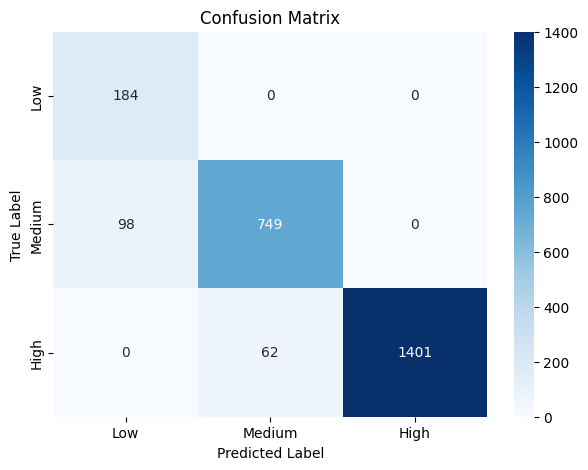

In [18]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel("Predicted Label")

plt.ylabel("True Label")

plt.title("Confusion Matrix")

plt.show()

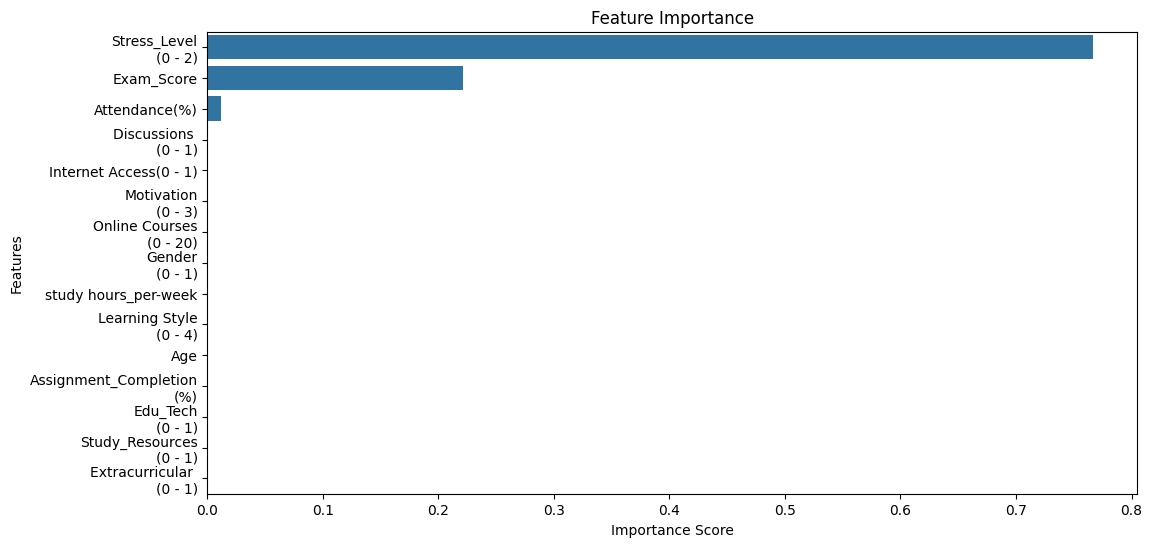

In [19]:
feature_importance = model.feature_importances_

importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': feature_importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(12,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=importance_df
)

plt.title("Feature Importance")

plt.xlabel("Importance Score")

plt.ylabel("Features")

plt.show()

In [20]:
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance Value': model.feature_importances_
})

feature_importance_df = feature_importance_df.sort_values(
    by='Importance Value',
    ascending=False
)

feature_importance_df = feature_importance_df.reset_index(drop=True)

print(feature_importance_df)

                       Feature  Importance Value
0        Stress_Level\n(0 - 2)      7.667598e-01
1                   Exam_Score      2.216845e-01
2                Attendance(%)      1.155578e-02
3        Discussions \n(0 - 1)      7.849610e-15
4       Internet Access(0 - 1)      7.713701e-15
5          Motivation\n(0 - 3)      5.458175e-15
6     Online Courses\n(0 - 20)      4.038929e-15
7              Gender\n(0 - 1)      3.839903e-15
8         study hours_per-week      3.835132e-15
9      Learning Style\n(0 - 4)      2.972538e-15
10                         Age      2.962619e-15
11  Assignment_Completion\n(%)      2.808401e-15
12           Edu_Tech\n(0 - 1)      2.290289e-15
13    Study_Resources\n(0 - 1)      1.414524e-15
14   Extracurricular \n(0 - 1)      0.000000e+00


In [21]:
explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

print("SHAP Values Generated")

SHAP Values Generated


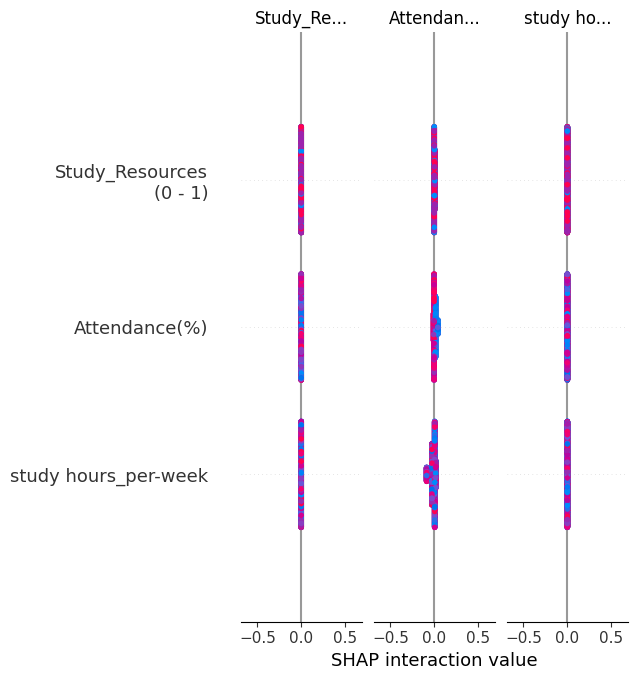

In [22]:
shap.summary_plot(shap_values, X_test)

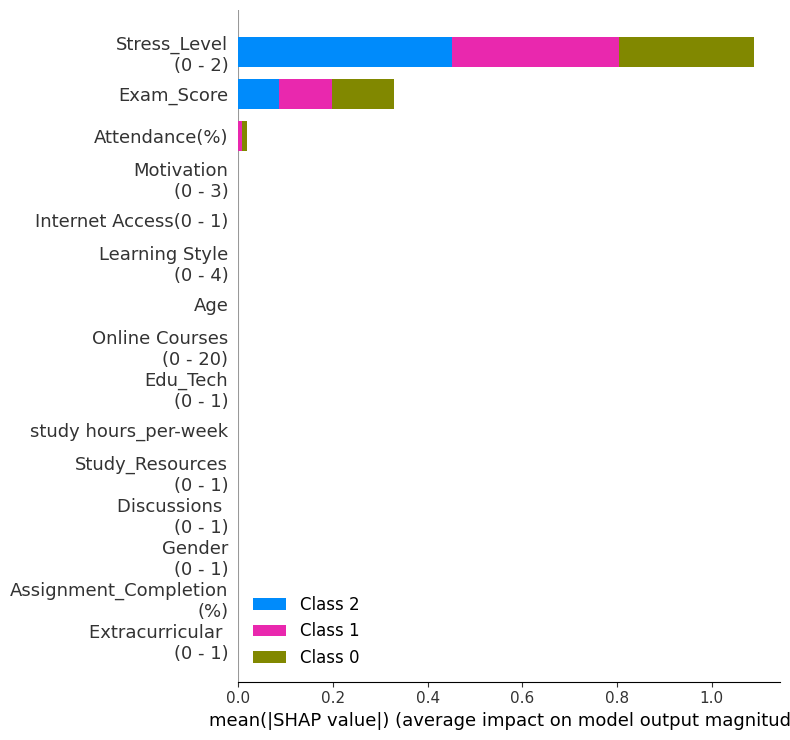

In [23]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type='bar'
)

In [24]:
label_map = {
    0: "Low Difficulty",
    1: "Medium Difficulty",
    2: "High Difficulty"
}

predictions = model.predict(X_test)

for i in range(len(X_test)):

    print("\n")
    print("=" * 70)

    print(f"STUDENT {i+1}")

    print("=" * 70)

    predicted_class = predictions[i]

    predicted_label = label_map[predicted_class]

    print(f"\nPredicted Difficulty Level : {predicted_label}")

    student_data = X_test.iloc[i]


    student_shap = shap_values[i][:, predicted_class]

    shap_df = pd.DataFrame({
        'Feature': X_test.columns,
        'SHAP Value': student_shap,
        'Actual Value': student_data.values
    })

    shap_df['Impact'] = shap_df['SHAP Value'].apply(
        lambda x: 'Increased Difficulty'
        if x > 0
        else 'Reduced Difficulty'
    )

    shap_df = shap_df.reindex(
        shap_df['SHAP Value'].abs().sort_values(
            ascending=False
        ).index
    )

    top_features = shap_df.head(5)

    print("\nExplanation :\n")

    for _, row in top_features.iterrows():

        feature = row['Feature']

        impact = row['Impact']


        feature = re.sub(r'\(.*?\)', '', feature)

        feature = feature.strip()

        if feature == 'Stress_Level':

            if impact == 'Increased Difficulty':

                print(
                    "- Higher stress level contributed to increasing the student's learning difficulty."
                )

            else:

                print(
                    "- Lower stress level helped reduce the student's learning difficulty."
                )

        elif feature == 'Exam_Score':

            if impact == 'Increased Difficulty':

                print(
                    "- Lower exam performance contributed to higher learning difficulty."
                )

            else:

                print(
                    "- Better exam performance helped reduce learning difficulty."
                )

        elif feature == 'Attendance':

            if impact == 'Increased Difficulty':

                print(
                    "- Poor attendance contributed to increasing learning difficulty."
                )

            else:

                print(
                    "- Good attendance helped reduce learning difficulty."
                )

        elif feature == 'Assignment_Completion':

            if impact == 'Increased Difficulty':

                print(
                    "- Incomplete assignments contributed to higher learning difficulty."
                )

            else:

                print(
                    "- Regular assignment completion helped reduce learning difficulty."
                )

        elif feature == 'Study_Hours':

            if impact == 'Increased Difficulty':

                print(
                    "- Fewer study hours contributed to increased learning difficulty."
                )

            else:

                print(
                    "- Consistent study hours helped reduce learning difficulty."
                )

        else:

            if impact == 'Increased Difficulty':

                print(
                    f"- {feature} contributed to increasing the student's learning difficulty."
                )

            else:

                print(
                    f"- {feature} helped reduce the student's learning difficulty."
                )

Streaming output truncated to the last 5000 lines.
- Lower exam performance contributed to higher learning difficulty.
- Poor attendance contributed to increasing learning difficulty.
- Higher stress level contributed to increasing the student's learning difficulty.
- Extracurricular helped reduce the student's learning difficulty.
- Motivation helped reduce the student's learning difficulty.


STUDENT 2162

Predicted Difficulty Level : High Difficulty

Explanation :

- Higher stress level contributed to increasing the student's learning difficulty.
- Lower exam performance contributed to higher learning difficulty.
- Good attendance helped reduce learning difficulty.
- Motivation contributed to increasing the student's learning difficulty.
- Internet Access contributed to increasing the student's learning difficulty.


STUDENT 2163

Predicted Difficulty Level : Medium Difficulty

Explanation :

- Lower exam performance contributed to higher learning difficulty.
- Higher stress level c

In [25]:
results_df = pd.DataFrame({
    'Actual Difficulty': y_test,
    'Predicted Difficulty': predictions
})

results_df['Actual Difficulty'] = (
    results_df['Actual Difficulty']
    .map(label_map)
)

results_df['Predicted Difficulty'] = (
    results_df['Predicted Difficulty']
    .map(label_map)
)

results_df.head(20)

,Actual Difficulty,Predicted Difficulty
6559,Medium Difficulty,Medium Difficulty
9270,High Difficulty,High Difficulty
3804,High Difficulty,High Difficulty
114,Medium Difficulty,Medium Difficulty
848,High Difficulty,High Difficulty
10180,Medium Difficulty,Medium Difficulty
7430,High Difficulty,High Difficulty
10149,High Difficulty,High Difficulty
7952,Medium Difficulty,Medium Difficulty
11176,Medium Difficulty,Medium Difficulty


In [26]:
results_df.to_csv(
    'final project.csv',
    index=False
)

print("Results Saved Successfully")

Results Saved Successfully


In [27]:
from google.colab import files

files.download('final project.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>